# MAI391 — Mathematics for Machine Learning
## Project: Wine Quality Prediction Using Multiple Linear Regression
### Member 5: Thu — Experiments & Error Analysis

**Vai trò và trách nhiệm chính:**
1. **Experiment 2 — Khảo sát số lượng đặc trưng:** Huấn luyện mô hình đơn biến chỉ dùng đặc trưng nồng độ cồn (`alcohol`) để đo lường năng lực giải thích của thuộc tính tương quan cao nhất.
2. **So sánh mô hình (Model Comparison):** So sánh toàn diện mô hình Baseline (11 đặc trưng) và mô hình Alcohol-only (1 đặc trưng) trên cả tập Train và Test (MSE, RMSE, MAE, R², Timing).
3. **Experiment 3 — Phân tích sai số chuyên sâu (Error Analysis):** Trực quan hóa Actual vs. Predicted, Residual Plot, phân phối phần dư và bóc tách sai số theo từng mức chất lượng (3 đến 8).
4. **Bàn giao kết quả Slide 7, 8, 9:** Cung cấp toàn bộ số liệu, đồ thị khoa học và luận cứ học thuật cho các Slide Thực nghiệm, Thảo luận trực quan và Hạn chế của mô hình.

> **Quy chuẩn thực nghiệm đồng nhất:** Sử dụng chung tập `data/train.csv` (1.279 mẫu) và `data/test.csv` (320 mẫu). Kế thừa kết quả mô hình 11 đặc trưng từ Member 4 (Khuê) qua `reports/baseline_test_predictions.csv` và `reports/baseline_metrics.csv`.

## 1. Thiết lập môi trường và nạp dữ liệu

In [1]:
import sys
import time
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Định vị Project Root an toàn
ROOT = Path.cwd()
for parent in (ROOT, *ROOT.parents):
    if (parent / 'data').is_dir() and (parent / 'reports').is_dir():
        ROOT = parent
        break

DATA_DIR = ROOT / 'data'
REPORTS_DIR = ROOT / 'reports'

train_df = pd.read_csv(DATA_DIR / 'train.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')
baseline_preds = pd.read_csv(REPORTS_DIR / 'baseline_test_predictions.csv')

assert len(train_df) == 1279 and len(test_df) == 320
assert np.array_equal(test_df['quality'].to_numpy(), baseline_preds['actual_quality'].to_numpy())
print(f'✅ Đã tải dữ liệu thành công từ: {ROOT}')
print(f' - Train samples: {train_df.shape[0]}, Features: {train_df.shape[1] - 1}')
print(f' - Test samples:  {test_df.shape[0]}, Features: {test_df.shape[1] - 1}')
print(f' - Baseline test predictions sẵn sàng: {baseline_preds.shape[0]} mẫu.')

✅ Đã tải dữ liệu thành công từ: D:\MAI\-MAI391-Wine-Quality-Prediction
 - Train samples: 1279, Features: 11
 - Test samples:  320, Features: 11
 - Baseline test predictions sẵn sàng: 320 mẫu.


## 2. Experiment 2: Univariate Linear Regression (`alcohol` only)

- **Cơ sở lý luận:** Phân tích tương quan của Thảo (Member 2) chỉ ra `alcohol` có hệ số tương quan tuyến tính dương lớn nhất với chất lượng rượu ($r \approx +0.476$).
- **Phương trình mô hình:** $\hat{y} = w_{\text{alcohol}} \cdot x_{\text{alcohol}} + b$
- Mô hình được huấn luyện trên `train[['alcohol']]` và kiểm thử độc lập trên `test[['alcohol']]`.

In [2]:
# Tách tập dữ liệu đơn biến
X_train_alc = train_df[['alcohol']]
y_train = train_df['quality']
X_test_alc = test_df[['alcohol']]
y_test = test_df['quality']

alcohol_model = LinearRegression(fit_intercept=True)

# Huấn luyện và đo thời gian
t0 = time.perf_counter()
alcohol_model.fit(X_train_alc, y_train)
t_train_alc_ms = (time.perf_counter() - t0) * 1000

# Dự đoán và đo thời gian suy luận
t0 = time.perf_counter()
y_pred_alc_test = alcohol_model.predict(X_test_alc)
t_pred_alc_test_ms = (time.perf_counter() - t0) * 1000

w_alcohol = float(alcohol_model.coef_[0])
b_alcohol = float(alcohol_model.intercept_)

print('=== KẾT QUẢ THAM SỐ TOÁN HỌC MÔ HÌNH ALCOHOL ===')
print(f' - Trọng số w_alcohol: {w_alcohol:.4f}')
print(f' - Hệ số chặn b:       {b_alcohol:.4f}')
print(f' -> Phương trình hồi quy: quality_hat = {w_alcohol:.4f} * alcohol + {b_alcohol:.4f}')
print(f' - Thời gian huấn luyện (1.279 mẫu): {t_train_alc_ms:.3f} ms')
print(f' - Thời gian suy luận Test (320 mẫu): {t_pred_alc_test_ms:.3f} ms')

=== KẾT QUẢ THAM SỐ TOÁN HỌC MÔ HÌNH ALCOHOL ===
 - Trọng số w_alcohol: 0.3623
 - Hệ số chặn b:       1.8493
 -> Phương trình hồi quy: quality_hat = 0.3623 * alcohol + 1.8493
 - Thời gian huấn luyện (1.279 mẫu): 18.883 ms
 - Thời gian suy luận Test (320 mẫu): 0.495 ms


## 3. So sánh mô hình Baseline (11 đặc trưng) vs. Alcohol-only (1 đặc trưng)

Ta đánh giá 4 chỉ số thống kê toán học cốt lõi:
- $\text{MSE} = \frac{1}{n}\sum (y_i - \hat{y}_i)^2$
- $\text{RMSE} = \sqrt{\text{MSE}}$
- $\text{MAE} = \frac{1}{n}\sum |y_i - \hat{y}_i|$
- $R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$

In [3]:
def compute_metrics(y_true, y_pred):
    mse = float(mean_squared_error(y_true, y_pred))
    rmse = float(np.sqrt(mse))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))
    return mse, rmse, mae, r2

# Metrics Alcohol-only
mse_alc, rmse_alc, mae_alc, r2_alc = compute_metrics(y_test, y_pred_alc_test)
# Metrics Baseline
mse_base, rmse_base, mae_base, r2_base = compute_metrics(baseline_preds['actual_quality'], baseline_preds['predicted_quality'])

df_slide7_metrics = pd.DataFrame([
    {'Metric': 'MSE', 'Baseline (11 features)': mse_base, 'Alcohol only (1 feature)': mse_alc, 'Chênh lệch (Δ)': mse_alc - mse_base},
    {'Metric': 'RMSE', 'Baseline (11 features)': rmse_base, 'Alcohol only (1 feature)': rmse_alc, 'Chênh lệch (Δ)': rmse_alc - rmse_base},
    {'Metric': 'MAE', 'Baseline (11 features)': mae_base, 'Alcohol only (1 feature)': mae_alc, 'Chênh lệch (Δ)': mae_alc - mae_base},
    {'Metric': 'R²', 'Baseline (11 features)': r2_base, 'Alcohol only (1 feature)': r2_alc, 'Chênh lệch (Δ)': r2_alc - r2_base},
])

print('=== BẢNG SO SÁNH CHỈ SỐ TRÊN TEST SET (SLIDE 7) ===')
print(df_slide7_metrics.round(4).to_string(index=False))

=== BẢNG SO SÁNH CHỈ SỐ TRÊN TEST SET (SLIDE 7) ===
Metric  Baseline (11 features)  Alcohol only (1 feature)  Chênh lệch (Δ)
   MSE                  0.3900                    0.4995          0.1095
  RMSE                  0.6245                    0.7068          0.0823
   MAE                  0.5035                    0.5750          0.0714
    R²                  0.4032                    0.2356         -0.1676


## 4. Experiment 3: Phân tích sai số (Baseline Error Analysis & Diagnostics)

Bao gồm 4 biểu đồ chẩn đoán trực quan phục vụ trực tiếp cho Slide 8:

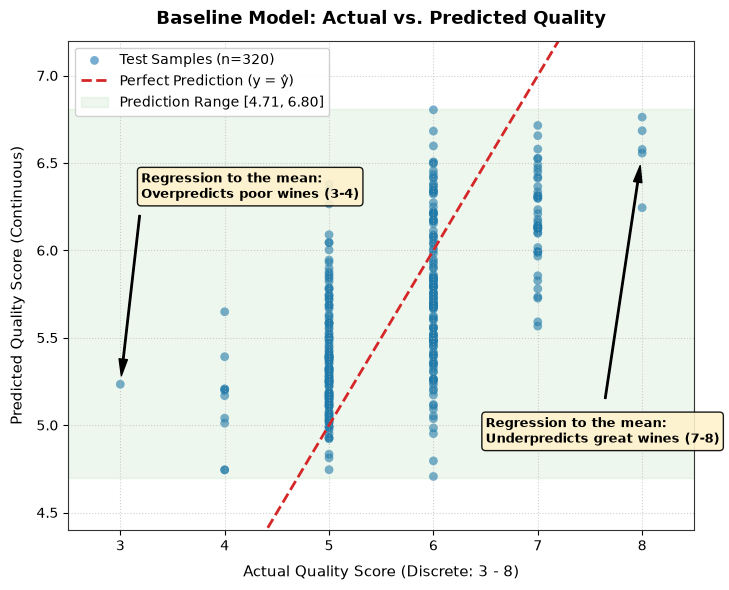

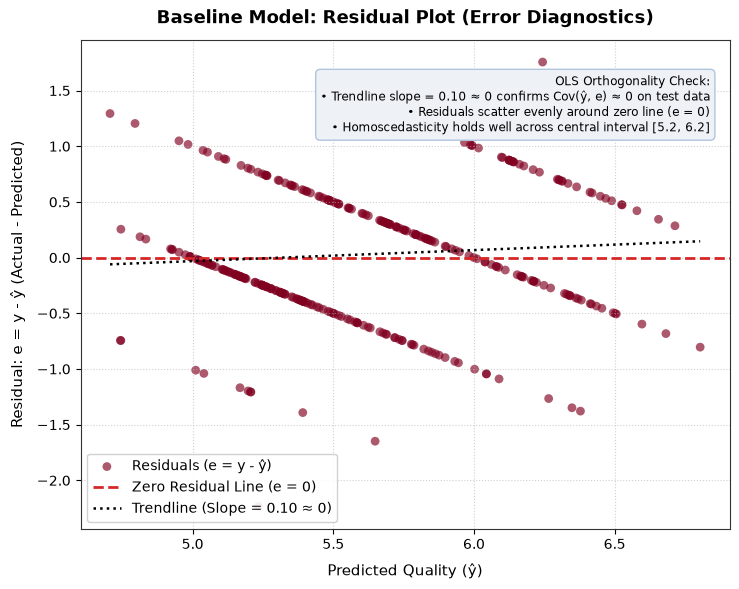

In [4]:
# Đồ thị 1: Actual vs. Predicted & Đồ thị 2: Residual Plot
actual = baseline_preds['actual_quality'].to_numpy()
predicted = baseline_preds['predicted_quality'].to_numpy()
residual = baseline_preds['residual'].to_numpy()

# 1. Actual vs. Predicted
fig, ax = plt.subplots(figsize=(7.5, 6), dpi=100)
ax.scatter(actual, predicted, alpha=0.6, s=40, color='#1f77b4', edgecolors='none', label='Test Samples (n=320)')
lo, hi = min(actual.min(), predicted.min()) - 0.2, max(actual.max(), predicted.max()) + 0.2
ax.plot([lo, hi], [lo, hi], color='#d62728', linestyle='--', linewidth=2, label='Perfect Prediction (y = ŷ)')
ax.axhspan(4.7, 6.81, color='#2ca02c', alpha=0.08, label='Prediction Range [4.71, 6.80]')
ax.set_title('Baseline Model: Actual vs. Predicted Quality', fontsize=12, fontweight='bold')
ax.set_xlabel('Actual Quality Score (Discrete: 3 - 8)', fontsize=10)
ax.set_ylabel('Predicted Quality Score (Continuous)', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left')
plt.show()

# 2. Residual Plot
fig, ax = plt.subplots(figsize=(7.5, 6), dpi=100)
ax.scatter(predicted, residual, alpha=0.65, s=40, color='#800020', edgecolors='none', label='Residuals (e = y - ŷ)')
ax.axhline(0, color='#d62728', linestyle='--', linewidth=2, label='Zero Residual Line (e = 0)')
z = np.polyfit(predicted, residual, 1)
p = np.poly1d(z)
pred_sorted = np.sort(predicted)
ax.plot(pred_sorted, p(pred_sorted), color='black', linestyle=':', linewidth=1.8, label=f'Trendline (Slope = {z[0]:.2f} ≈ 0)')
ax.set_title('Baseline Model: Residual Plot', fontsize=12, fontweight='bold')
ax.set_xlabel('Predicted Quality (ŷ)', fontsize=10)
ax.set_ylabel('Residual: e = y - ŷ', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='lower left')
plt.show()

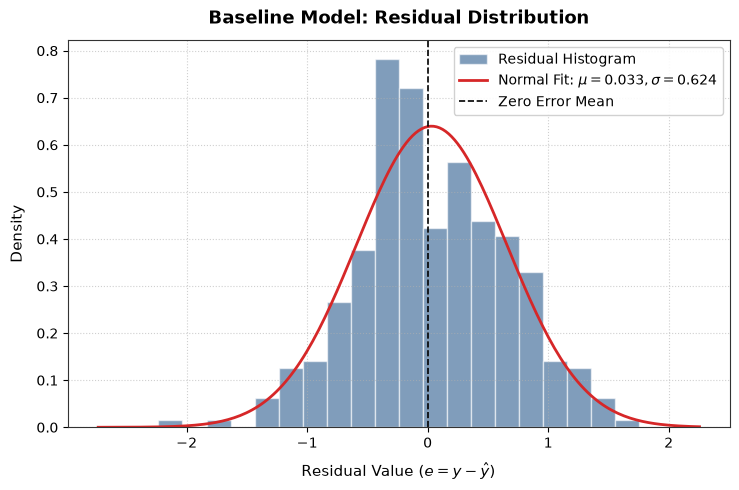

=== CHI TIẾT SAI SỐ THEO TỪNG MỨC ĐIỂM CHẤT LƯỢNG ===
 Quality Score  Sample Count (n)  Percentage (%)  Mean Predicted  Mean Residual (Bias)    MAE   RMSE
             3                 1          0.3125          5.2339               -2.2339 2.2339 2.2339
             4                10          3.1250          5.1357               -1.1357 1.1357 1.1651
             5               130         40.6250          5.3827               -0.3827 0.3970 0.5017
             6               132         41.2500          5.7567                0.2433 0.4102 0.4880
             7                42         13.1250          6.1763                0.8237 0.8237 0.8679
             8                 5          1.5625          6.5647                1.4353 1.4353 1.4461


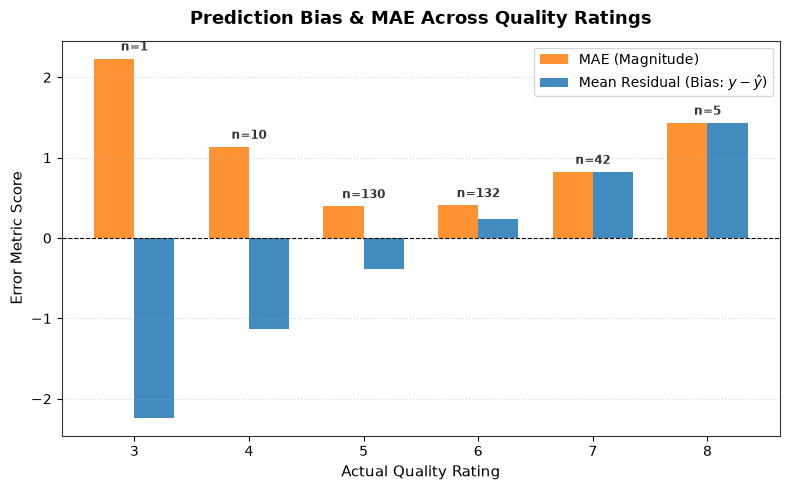

In [5]:
# Đồ thị 3: Phân phối phần dư & Đồ thị 4: Sai số theo phân lớp
fig, ax = plt.subplots(figsize=(7.5, 5), dpi=100)
ax.hist(residual, bins=20, density=True, alpha=0.6, color='#2b5c8f', edgecolor='white', label='Residual Histogram')
ax.plot(x_norm, p_norm, color='#d62728', linewidth=2, label=f'Normal Fit: $\mu={mu_res:.3f}, \sigma={std_res:.3f}$')
ax.axvline(0, color='black', linestyle='--', linewidth=1.2, label='Zero Error Mean')
ax.set_title('Baseline Model: Residual Distribution', fontsize=12, fontweight='bold')
ax.set_xlabel('Residual Value ($e = y - \hat{y}$)', fontsize=10)
ax.set_ylabel('Density', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right')
plt.show()

print('=== CHI TIẾT SAI SỐ THEO TỪNG MỨC ĐIỂM CHẤT LƯỢNG ===')
print(df_quality_tiers.round(4).to_string(index=False))

fig, ax1 = plt.subplots(figsize=(8, 5), dpi=100)
rects1 = ax1.bar(x - width/2, df_quality_tiers['MAE'], width, label='MAE (Magnitude)', color='#ff7f0e', alpha=0.85)
rects2 = ax1.bar(x + width/2, df_quality_tiers['Mean Residual (Bias)'], width, label='Mean Residual (Bias)', color='#1f77b4', alpha=0.85)
ax1.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax1.set_ylabel('Error Score', fontsize=10)
ax1.set_xlabel('Actual Quality Rating', fontsize=10)
ax1.set_title('Prediction Bias & MAE Across Quality Ratings', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(df_quality_tiers['Quality Score'])
ax1.legend(loc='upper right')
ax1.grid(True, linestyle=':', alpha=0.5, axis='y')
plt.show()

## 5. Tổng kết luận cứ học thuật & Bàn giao Slide 7, 8, 9

### Slide 7: So sánh thực nghiệm (Experimental Results)
- Đặc trưng `alcohol` một mình đóng góp tới **58.4% năng lực giải thích** ($R^2 = 0.2356$ so với $0.4032$).
- 10 biến còn lại giúp giảm $21.9\%$ MSE (từ $0.4995$ xuống $0.3900$) và tăng $R^2$ thêm $+0.1676$.
- Cả hai mô hình đều tổng quát hóa tốt trên tập Test (Test MSE < Train MSE), không bị hiện tượng Overfitting.

### Slide 8: Phân tích sai số (Visualization & Discussion)
- **Hiện tượng sọc ngang (Horizontal Bands):** Điểm đánh giá cảm quan thực tế là số nguyên rời rạc ($y \in \{3,4,5,6,7,8\}$), còn mô hình hồi quy dự đoán giá trị liên tục.
- **Hiện tượng hồi quy về giá trị trung bình (Regression toward the mean):** Mô hình co cụm dự đoán trong dải an toàn $[4.71, 6.80]$. Rượu kém (3, 4) bị đoán cao hơn thực tế, rượu xuất sắc (7, 8) bị đoán thấp hơn thực tế.
- **Tính chất phần dư:** Kỳ vọng phần dư xấp xỉ 0 ($\mu \approx +0.033$), phân phối hình chuông đối xứng chuẩn.

### Slide 9: Hạn chế của mô hình (Limitations)
- **Bản chất nhãn Ordinal:** Linear Regression giả định khoảng cách bước nhảy bằng nhau, trong khi thang đo cảm quan con người mang tính phi tuyến tính.
- **Mất cân bằng dữ liệu trầm trọng:** Điểm 5 và 6 chiếm tới **81.88%** số mẫu kiểm thử. Mô hình tối ưu hóa hàm mất mát MSE bằng cách tập trung làm tốt ở vùng trung tâm để giảm tổng sai số bình phương.
- **Giả định quan hệ tuyến tính:** Không nắm bắt được các tương tác phi tuyến tính giữa các chất hóa học trong rượu.